# NHANES 2021–2023 — Giai đoạn 3, Bước 6A: Model Evaluation (Validation)

**Người thực hành:** Bạn tự chạy trên Jupyter Notebook. **Notebook này chưa được thực thi** và **không huấn luyện lại mô hình**.

**Mục tiêu:** phân tích mô hình `LogisticRegression` đã được chọn ở Bước 5, xem ROC / Precision–Recall, confusion matrix, calibration, phân tích theo nhóm, và **thử các ngưỡng quyết định trên Validation**.

> **RANH GIỚI:** Không mở / đánh giá `test_holdout_DO_NOT_TUNE.csv` ở Bước 6A. Không gọi `.fit()`. Chưa chốt model hay threshold cuối cùng; sau khi xem kết quả Validation và chốt ngưỡng, mới thực hiện Bước 6B một lần duy nhất trên Test.

Nhãn nghiên cứu là **HbA1c ≥ 5,7%**, không phải chẩn đoán tiểu đường type 2 hoặc xác suất mắc bệnh trong tương lai. Các metric hiện tại **chưa tính đến thiết kế mẫu/trọng số khảo sát NHANES**; không sử dụng lâm sàng.

## 0. Các file cần có trước khi chạy

Giữ nguyên những file đã được **chính bạn** tạo ra ở Bước 5:

- `data/outputs/model_training/validation.csv`
- `data/outputs/model_training/step5_metadata.json`
- `data/outputs/model_training/step5_validation_metrics.csv`
- `models/baseline/nhanes_hba1c_baseline_step5.joblib`

**Cảnh báo an toàn:** `joblib.load()` chỉ dùng với file tin cậy bạn tự tạo, tuyệt đối không tải `.joblib` từ nguồn không rõ ràng.

Nếu chưa có package, tạo ô Jupyter riêng: `%pip install scikit-learn pandas numpy matplotlib joblib`. Nếu đổi phiên bản sklearn, kiểm tra khả năng tương thích với model đã lưu.

In [1]:
from pathlib import Path
import json, platform, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib
from IPython.display import display

cwd = Path.cwd().resolve()
if (cwd / "data" / "outputs" / "model_training").is_dir():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data" / "outputs" / "model_training").is_dir():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError("Mở Jupyter từ thư mục 03-ML-Research hoặc 03-ML-Research/notebooks")

TRAIN_OUT = PROJECT_ROOT / "data" / "outputs" / "model_training"
EVAL_OUT = PROJECT_ROOT / "data" / "outputs" / "model_evaluation" / "validation_6a"
MODEL_FILE = PROJECT_ROOT / "models" / "baseline" / "nhanes_hba1c_baseline_step5.joblib"
META_FILE = TRAIN_OUT / "step5_metadata.json"
VAL_FILE = TRAIN_OUT / "validation.csv"
METRICS_FILE = TRAIN_OUT / "step5_validation_metrics.csv"
for path in (META_FILE, VAL_FILE, METRICS_FILE, MODEL_FILE):
    if not path.exists():
        raise FileNotFoundError(f"Thiếu file Bước 5: {path}")
EVAL_OUT.mkdir(parents=True, exist_ok=True)
print("Python", platform.python_version(), "| pandas", pd.__version__, "| sklearn", sklearn.__version__)
print("Thư mục kết quả bước 6A:", EVAL_OUT)
print("Không dùng dữ liệu Test trong bước này.")

Python 3.13.9 | pandas 3.0.0 | sklearn 1.8.0
Thư mục kết quả bước 6A: C:\Users\ThinkPad\Multi-Agent_Du_doan_benh_tieu_duong\GĐ3\03-ML-Research\data\outputs\model_evaluation\validation_6a
Không dùng dữ liệu Test trong bước này.


## 1. Nạp lại model đã huấn luyện (không `.fit()`)

Dùng `step5_metadata.json` để kiểm tra đặc trưng, tên model, số mẫu, phiên bản. Nếu phiên bản scikit-learn khác với lần huấn luyện, kết quả có thể không tái hiện chính xác; nên mở trong cùng môi trường Bước 5.

In [2]:
meta = json.loads(META_FILE.read_text(encoding="utf-8"))
FEATURES = ["RIDAGEYR", "RIAGENDR", "BMXBMI"]
TARGET = "a1c_ge_57_candidate"
assert meta.get("features") == FEATURES, "Feature schema thay đổi so với Bước 5"
assert meta.get("selected_model") == "LogisticRegression", "Model được chọn không trùng kết quả bạn đã gửi"
assert meta.get("test_metrics") is None, "Metadata cho thấy test đã chạy: kiểm tra lại trước khi tiếp tục"
if sklearn.__version__ != meta.get("sklearn_version"):
    raise RuntimeError("Phiên bản sklearn khác lần train. Hãy dùng lại đúng môi trường Jupyter Bước 5.")

# CẢNH BÁO: Chỉ joblib.load artifact do CHÍNH BẠN tạo ở Bước 5
model = joblib.load(MODEL_FILE)
val = pd.read_csv(VAL_FILE)
assert len(val) == meta.get("validation_sample_count") == 705, "Số mẫu Validation không khớp Bước 5"
assert {"SEQN", TARGET, *FEATURES}.issubset(val.columns), "Thiếu cột validation"
assert val["SEQN"].is_unique and val["SEQN"].notna().all(), "SEQN validation thiếu hoặc trùng"
assert val[TARGET].notna().all() and set(val[TARGET].unique()) <= {0, 1}, "Nhãn phải 0/1"
assert list(model.classes_) == [0,1], "Model classes_ phải là [0, 1]"
X_val = val[FEATURES]
y_val = val[TARGET].astype(int)
proba = model.predict_proba(X_val)[:, 1]
assert np.isfinite(proba).all() and ((0 <= proba) & (proba <= 1)).all()
print("Model:", meta["selected_model"], "| Validation:", len(val), "| nhãn 1:", int(y_val.sum()))
print("Model SHA256:", hashlib.sha256(MODEL_FILE.read_bytes()).hexdigest()[:20], "...")
print("Không gọi fit; không đọc test.")

Model: LogisticRegression | Validation: 705 | nhãn 1: 208
Model SHA256: 31e9c94b0f14369be792 ...
Không gọi fit; không đọc test.


## 2. Xác minh chính xác kết quả Bước 5 trên Validation

Dùng ngưỡng 0,5 để tái hiện Precision, Recall, F1, ROC-AUC, Average Precision (AP), Brier và Confusion Matrix. Nếu sai khác đáng kể so với ảnh bạn gửi, dừng và kiểm tra đường dẫn/model.

In [3]:
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                             f1_score, fbeta_score, roc_auc_score, average_precision_score,
                             brier_score_loss, roc_curve, precision_recall_curve)

def evaluate_at_threshold(y, p, threshold):
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0,1]).ravel()
    return {
        "threshold": float(round(threshold, 4)),
        "precision": float(precision_score(y, pred, zero_division=0)),
        "recall": float(recall_score(y, pred, zero_division=0)),
        "specificity": float(tn/(tn+fp)) if (tn+fp)>0 else np.nan,
        "f1": float(f1_score(y, pred, zero_division=0)),
        "f2": float(fbeta_score(y, pred, beta=2, zero_division=0)),
        "accuracy": float(accuracy_score(y, pred)),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "pred_positive_n": int(pred.sum())
    }

baseline = evaluate_at_threshold(y_val, proba, 0.5)
print("ROC-AUC:", round(roc_auc_score(y_val,proba),4))
print("Average Precision (AP):", round(average_precision_score(y_val,proba),4))
print("Brier Score:", round(brier_score_loss(y_val,proba),4))
print("Threshold=0.5:")
display(pd.DataFrame([baseline]).round(4))
expected_cm = {"tn":454, "fp":43, "fn":174, "tp":34}
assert all(baseline[k] == v for k,v in expected_cm.items()), (
    f"Không tái hiện Confusion Matrix Bước 5: {baseline}; dừng và kiểm tra"
)
print("Đã tái hiện Confusion Matrix Bước 5.")

ROC-AUC: 0.7173
Average Precision (AP): 0.4415
Brier Score: 0.1868
Threshold=0.5:


,threshold,precision,recall,specificity,f1,f2,accuracy,tn,fp,fn,tp,pred_positive_n
0,0.5,0.4416,0.1635,0.9135,0.2386,0.187,0.6922,454,43,174,34,77


Đã tái hiện Confusion Matrix Bước 5.


## 3. Trực quan hóa ROC và Precision–Recall

ROC-AUC và AP không phụ thuộc vào một ngưỡng đơn lẻ. **AP không phải AUC hình thang của PR curve**. Xem cả đường baseline prevalence (tỷ lệ nhãn 1 trong Validation).

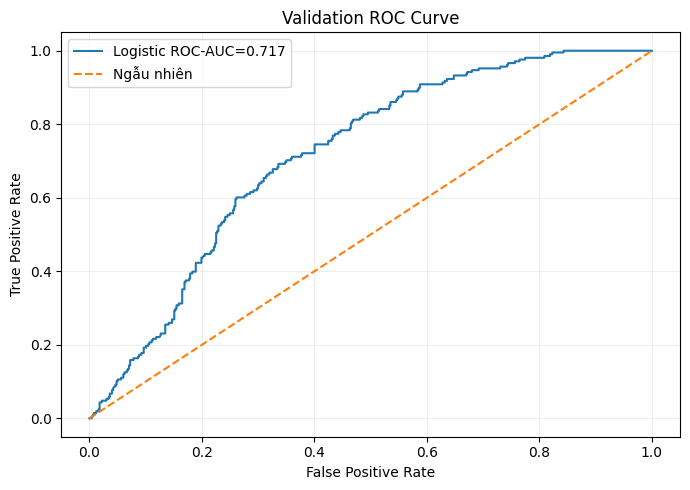

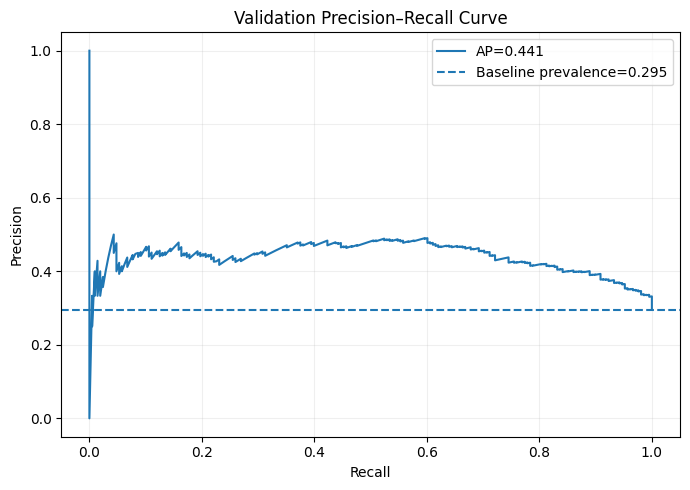

In [4]:
fpr, tpr, _ = roc_curve(y_val, proba)
pr_precision, pr_recall, _ = precision_recall_curve(y_val, proba)
prevalence = y_val.mean()

fig, ax = plt.subplots(figsize=(7,5))
ax.plot(fpr, tpr, label=f"Logistic ROC-AUC={roc_auc_score(y_val,proba):.3f}")
ax.plot([0,1], [0,1], "--", label="Ngẫu nhiên")
ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="Validation ROC Curve")
ax.legend(); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(EVAL_OUT/"06a_roc_curve.png", dpi=160); plt.show()

fig, ax = plt.subplots(figsize=(7,5))
ax.plot(pr_recall, pr_precision, label=f"AP={average_precision_score(y_val,proba):.3f}")
ax.axhline(prevalence, ls="--", label=f"Baseline prevalence={prevalence:.3f}")
ax.set(xlabel="Recall", ylabel="Precision", title="Validation Precision–Recall Curve")
ax.legend(); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(EVAL_OUT/"06a_precision_recall_curve.png", dpi=160); plt.show()

## 4. Phân tích trade-off của decision threshold **trên Validation**

`0.5` là ngưỡng mặc định, không nhất thiết phù hợp với nhiệm vụ sàng lọc nghiên cứu. Giảm ngưỡng thường tăng Recall nhưng cũng tăng False Positive.

Bảng này chỉ để **khảo sát**. Chưa có threshold nào được phê duyệt cho triển khai y tế. Không dùng Test để thử threshold.

,threshold,recall,precision,specificity,f1,f2,fp,fn,pred_positive_pct
0,0.100,0.995,0.335,0.175,0.502,0.714,410,1,87.518
1,0.125,0.962,0.351,0.256,0.514,0.713,370,8,80.851
2,0.150,0.933,0.372,0.340,0.532,0.716,328,14,74.043
3,0.175,0.909,0.387,0.396,0.542,0.715,300,19,69.362
4,0.200,0.870,0.399,0.451,0.547,0.704,273,27,64.397
5,0.225,0.832,0.410,0.499,0.549,0.690,249,35,59.858
6,0.250,0.784,0.422,0.551,0.549,0.669,223,45,54.752
7,0.275,0.721,0.434,0.606,0.542,0.637,196,58,49.078
8,0.300,0.683,0.461,0.666,0.550,0.623,166,66,43.688
9,0.325,0.620,0.467,0.704,0.533,0.582,147,79,39.149


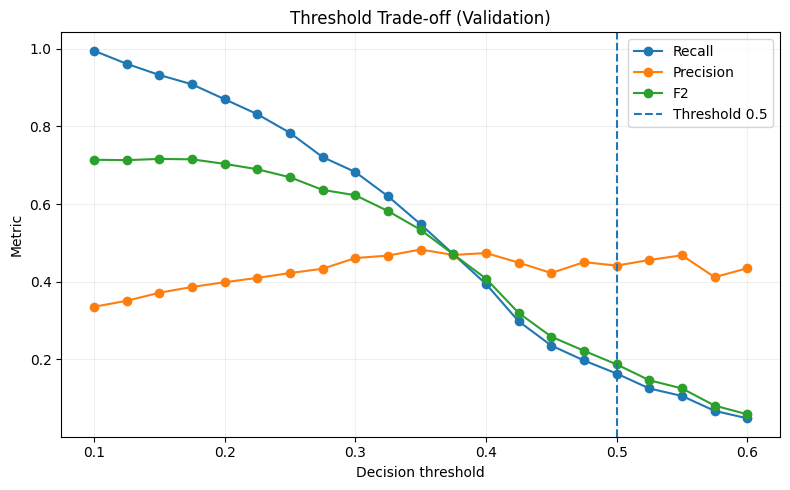

Các threshold thử nghiệm có Recall >= 0.70 (mốc kỹ thuật tham khảo, không phải chuẩn lâm sàng):


,threshold,recall,precision,specificity,f1,f2,fp,fn,pred_positive_pct
7,0.275,0.721,0.434,0.606,0.542,0.637,196,58,49.078
6,0.250,0.784,0.422,0.551,0.549,0.669,223,45,54.752
5,0.225,0.832,0.410,0.499,0.549,0.690,249,35,59.858
4,0.200,0.870,0.399,0.451,0.547,0.704,273,27,64.397
3,0.175,0.909,0.387,0.396,0.542,0.715,300,19,69.362
2,0.150,0.933,0.372,0.340,0.532,0.716,328,14,74.043
1,0.125,0.962,0.351,0.256,0.514,0.713,370,8,80.851


CHƯA chọn ngưỡng cuối cùng. Gửi bảng kết quả để cùng quyết định.


In [5]:
thresholds = np.round(np.arange(0.10, 0.625, 0.025), 3)
threshold_table = pd.DataFrame([evaluate_at_threshold(y_val, proba, float(t)) for t in thresholds])
threshold_table["pred_positive_pct"] = 100*threshold_table["pred_positive_n"]/len(val)
cols = ["threshold","recall","precision","specificity","f1","f2","fp","fn","pred_positive_pct"]
display(threshold_table[cols].round(3))
threshold_table.to_csv(EVAL_OUT/"06a_validation_thresholds.csv", index=False)

fig,ax = plt.subplots(figsize=(8,5))
ax.plot(threshold_table.threshold, threshold_table.recall, "o-",label="Recall")
ax.plot(threshold_table.threshold, threshold_table.precision, "o-",label="Precision")
ax.plot(threshold_table.threshold, threshold_table.f2, "o-",label="F2")
ax.axvline(0.5, ls="--", label="Threshold 0.5")
ax.set(xlabel="Decision threshold", ylabel="Metric", title="Threshold Trade-off (Validation)")
ax.legend(); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(EVAL_OUT/"06a_threshold_tradeoff.png",dpi=160); plt.show()

candidates = threshold_table.loc[threshold_table["recall"] >= 0.70, cols]
print("Các threshold thử nghiệm có Recall >= 0.70 (mốc kỹ thuật tham khảo, không phải chuẩn lâm sàng):")
if candidates.empty:
    print("Không có threshold trong grid đạt recall >= 0.70; cần xem lại mục tiêu và khả năng phân tách của model")
else:
    display(candidates.sort_values(["precision","f2"], ascending=False).head(7).round(3))
print("CHƯA chọn ngưỡng cuối cùng. Gửi bảng kết quả để cùng quyết định.")

## 5. Kiểm tra độ phù hợp của điểm số dự đoán (calibration, không huấn luyện)

Reliability diagram cho biết nhóm dự đoán ở mức điểm số nào có tần suất nhãn 1 thực tế tương ứng ra sao. Brier Score thấp hơn chưa đủ để kết luận calibration tốt hơn; cần xem biểu đồ và cỡ mẫu mỗi bin.

**Không áp dụng `CalibratedClassifierCV.fit()` trong bước này**, tránh vô tình train/fit trên Validation và gây leakage.

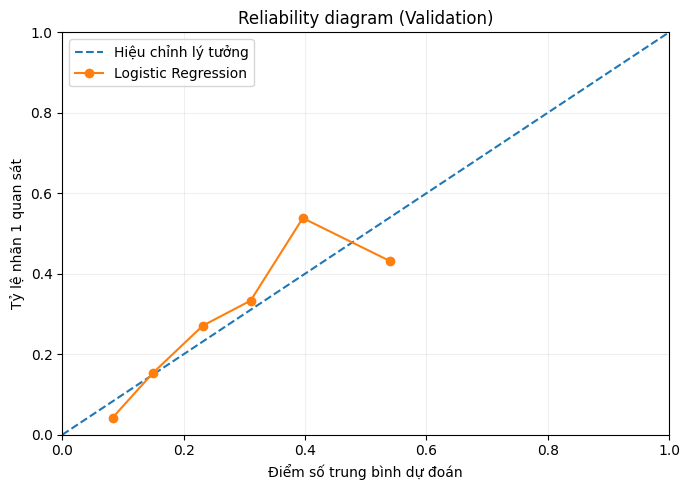

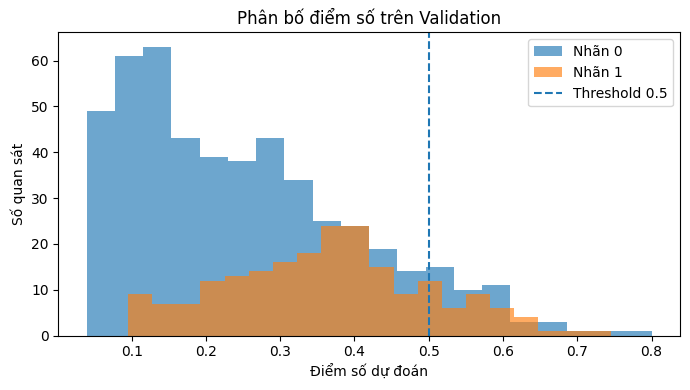

In [6]:
from sklearn.calibration import calibration_curve
fraction_pos, mean_pred = calibration_curve(y_val, proba, n_bins=6, strategy="quantile")
fig, ax = plt.subplots(figsize=(7,5))
ax.plot([0,1],[0,1],"--",label="Hiệu chỉnh lý tưởng")
ax.plot(mean_pred,fraction_pos,"o-",label="Logistic Regression")
ax.set(xlim=(0,1),ylim=(0,1),xlabel="Điểm số trung bình dự đoán",ylabel="Tỷ lệ nhãn 1 quan sát",title="Reliability diagram (Validation)")
ax.legend();ax.grid(alpha=.2)
fig.tight_layout();fig.savefig(EVAL_OUT/"06a_reliability_diagram.png",dpi=160);plt.show()

fig,ax=plt.subplots(figsize=(7,4))
ax.hist(proba[y_val.to_numpy()==0],bins=20,alpha=.65,label="Nhãn 0")
ax.hist(proba[y_val.to_numpy()==1],bins=20,alpha=.65,label="Nhãn 1")
ax.axvline(0.5,ls="--",label="Threshold 0.5")
ax.set(xlabel="Điểm số dự đoán",ylabel="Số quan sát",title="Phân bố điểm số trên Validation")
ax.legend()
fig.tight_layout();fig.savefig(EVAL_OUT/"06a_score_distribution.png",dpi=160);plt.show()

## 6. Phân tích nhóm tuổi, mã giới tính khảo sát (mô tả, chưa trọng số)

Các thống kê theo nhóm có thể thiếu ổn định nếu ít nhãn dương tính. Với `RIDAGEYR=80`, NHANES gộp nhóm người từ 80 tuổi trở lên. `RIAGENDR` lưu mã 1/2 của khảo sát.

Không tự suy ra sự khác biệt nhóm là nguyên nhân sinh học, không suy rộng sang dân số Việt Nam.

In [7]:
val_with_scores = val[["RIDAGEYR","RIAGENDR",TARGET]].copy()
val_with_scores["p1"] = proba
val_with_scores["age_band"] = pd.cut(val_with_scores["RIDAGEYR"],
    bins=[19,39,59,79, np.inf], labels=["20-39","40-59","60-79","80+"])
val_with_scores["gender_code"] = "code_" + val_with_scores["RIAGENDR"].astype("Int64").astype(str)

def describe_group(g):
    y = g[TARGET].astype(int)
    p = g.p1.to_numpy()
    z = evaluate_at_threshold(y,p,0.5)
    auc = roc_auc_score(y,p) if len(g)>=40 and y.sum()>=10 and (len(g)-y.sum())>=10 else np.nan
    return {"n":len(g),"positive_n":int(y.sum()), "recall_at_0_5":z["recall"],
            "precision_at_0_5":z["precision"], "roc_auc_cautious":auc}

subgroup_rows=[]
for col in ["age_band","gender_code"]:
    for group,g in val_with_scores.groupby(col, observed=True, dropna=False):
        subgroup_rows.append({"group_type":col,"group":str(group), **describe_group(g)})
subgroup_table=pd.DataFrame(subgroup_rows)
display(subgroup_table.round(3))
subgroup_table.to_csv(EVAL_OUT/"06a_validation_subgroups.csv",index=False)
print("Các nhóm nhỏ: chỉ mô tả, không kết luận mô hình công bằng/thiên lệch nếu chưa phân tích đủ.")

,group_type,group,n,positive_n,recall_at_0_5,precision_at_0_5,roc_auc_cautious
0,age_band,20-39,222,27,0.000,0.000,0.765
1,age_band,40-59,212,66,0.076,0.556,0.679
2,age_band,60-79,245,106,0.217,0.460,0.582
3,age_band,80+,26,9,0.667,0.353,NaN
4,gender_code,code_1,306,79,0.228,0.400,0.694
5,gender_code,code_2,399,129,0.124,0.500,0.748


Các nhóm nhỏ: chỉ mô tả, không kết luận mô hình công bằng/thiên lệch nếu chưa phân tích đủ.


## 7. Tổng hợp và lưu kết quả VALIDATION 6A

Notebook lưu CSV/ảnh về `data/outputs/model_evaluation/validation_6a/` và tệp summary JSON. **Không ghi vào `test_holdout_DO_NOT_TUNE.csv` và không đổi model artifact**.

Gửi cho ChatGPT output cuối (không cần gửi dữ liệu cá thể), `06a_validation_thresholds.csv`, `06a_reliability_diagram.png` và `06a_threshold_tradeoff.png` để phân tích trước khi quyết định ngưỡng và chuyển **Bước 6B – Final Holdout Test**.

In [8]:
summary = {
    "phase":"phase3_step6a",
    "validation_only":True,
    "test_opened":False,
    "fit_executed":False,
    "model": meta["selected_model"],
    "model_sha256": hashlib.sha256(MODEL_FILE.read_bytes()).hexdigest(),
    "validation_n": len(val),
    "validation_positive_n": int(y_val.sum()),
    "roc_auc_validation":float(roc_auc_score(y_val,proba)),
    "average_precision_validation":float(average_precision_score(y_val,proba)),
    "brier_validation":float(brier_score_loss(y_val,proba)),
    "threshold_0_5":baseline,
    "selected_threshold":None,
    "clinical_validation":"not performed",
    "external_validation":"not performed",
    "survey_weighted":"no",
}
(EVAL_OUT/"06a_validation_summary.json").write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding="utf-8")
print("===== BƯỚC 6A — VALIDATION EVALUATION (NGƯỜI DÙNG TỰ CHẠY) =====")
print("Model:",meta["selected_model"], "| n:",len(val), "| Positive:",int(y_val.sum()))
print("ROC-AUC:",round(summary["roc_auc_validation"],4), "| AP:",round(summary["average_precision_validation"],4), "| Brier:",round(summary["brier_validation"],4))
print("Threshold 0.5:", {k:round(v,4) if isinstance(v,float) else v for k,v in baseline.items()})
print("--- THRESHOLD TABLE (Validation) ---")
print(threshold_table[cols].round(3).to_string(index=False))
print("--- SUBGROUPS (Validation) ---")
print(subgroup_table.round(3).to_string(index=False))
print("Saved to:",EVAL_OUT)
print("TRAIN: NO | TEST: NOT RUN | EXTERNAL VALIDATION: NOT RUN")
print("===== KẾT THÚC 6A — GỬI OUTPUT CHO TÔI TRƯỚC KHI MỞ TEST =====")

===== BƯỚC 6A — VALIDATION EVALUATION (NGƯỜI DÙNG TỰ CHẠY) =====
Model: LogisticRegression | n: 705 | Positive: 208
ROC-AUC: 0.7173 | AP: 0.4415 | Brier: 0.1868
Threshold 0.5: {'threshold': 0.5, 'precision': 0.4416, 'recall': 0.1635, 'specificity': 0.9135, 'f1': 0.2386, 'f2': 0.187, 'accuracy': 0.6922, 'tn': 454, 'fp': 43, 'fn': 174, 'tp': 34, 'pred_positive_n': 77}
--- THRESHOLD TABLE (Validation) ---
 threshold  recall  precision  specificity    f1    f2  fp  fn  pred_positive_pct
     0.100   0.995      0.335        0.175 0.502 0.714 410   1             87.518
     0.125   0.962      0.351        0.256 0.514 0.713 370   8             80.851
     0.150   0.933      0.372        0.340 0.532 0.716 328  14             74.043
     0.175   0.909      0.387        0.396 0.542 0.715 300  19             69.362
     0.200   0.870      0.399        0.451 0.547 0.704 273  27             64.397
     0.225   0.832      0.410        0.499 0.549 0.690 249  35             59.858
     0.250   0.784  